In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import kagglehub
path = kagglehub.dataset_download("kaborg15/vibrent-clothes-rental-dataset")
print(path)

import os
print(os.listdir(path))

Using Colab cache for faster access to the 'vibrent-clothes-rental-dataset' dataset.
/kaggle/input/vibrent-clothes-rental-dataset
['outfits.csv', 'picture_triplets.csv', 'user_activity_triplets.csv', 'images', 'embeddings', 'additional_tabular_data']


In [ ]:
import shutil
dest = "/content/drive/MyDrive/project2/data"
shutil.copytree(path, dest, dirs_exist_ok=True)
print("Copied to Drive")

Copied to Drive


In [ ]:
import os

# Show the folder structure (top 3 levels) and how many files are in each folder
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 2:
        indent = "    " * depth
        folder_name = os.path.basename(root) or "root"
        print(f"{indent}{folder_name}/   ({len(files)} files)")

# Count all the image files
exts = ('.jpg', '.jpeg', '.png', '.webp')
images = [os.path.join(r, f) for r, _, fs in os.walk(path) for f in fs if f.lower().endswith(exts)]
print("\nTotal images found:", len(images))

7/   (3 files)
    additional_tabular_data/   (4 files)
    embeddings/   (0 files)
        EfficientNet_V2_L_final/   (50293 files)
    images/   (50293 files)

Total images found: 50293


# Data Cleaning

In [ ]:
import os

images_dir = os.path.join(path, "images")
all_files = sorted(os.listdir(images_dir))
print("Total files before cleaning:", len(all_files))

Total files before cleaning: 50293


In [ ]:
from PIL import Image
import hashlib
import pandas as pd
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

def check_image(filename):
    filepath = os.path.join(images_dir, filename)
    try:
        # Fingerprint of the file
        with open(filepath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        # Checks the image isn't corrupted
        with Image.open(filepath) as img:
            img.verify()
        # Checks the image isn't tiny
        with Image.open(filepath) as img:
            img.load()
            width, height = img.size
        if width < 50 or height < 50:
            return filename, file_hash, "too small", ""
        return filename, file_hash, "ok", ""
    except Exception as e:
        return filename, None, "invalid", str(e)[:80]

# Checks many images at once to save time
with ThreadPoolExecutor(max_workers=16) as executor:
    results = list(tqdm(executor.map(check_image, all_files), total=len(all_files)))

df = pd.DataFrame(results, columns=["filename", "hash", "status", "error"])
print(df["status"].value_counts())

  0%|          | 0/50293 [00:00<?, ?it/s]

status
ok           50279
too small       14
Name: count, dtype: int64


In [ ]:
valid = df[df["status"] == "ok"]
is_duplicate = valid.duplicated(subset="hash", keep="first")
clean = valid[~is_duplicate]

print("Before cleaning: ", len(df))
print("Invalid or too small: ", (df["status"] != "ok").sum())
print("Duplicates that were removed: ", is_duplicate.sum())
print("After cleaning: ", len(clean))

Before cleaning:  50293
Invalid or too small:  14
Duplicates that were removed:  18902
After cleaning:  31377


In [ ]:
cleaned_dir = "/content/cleaned_images"
os.makedirs(cleaned_dir, exist_ok=True)

def save_clean(filename):
    src = os.path.join(images_dir, filename)
    new_name = os.path.splitext(filename)[0] + ".jpg"
    with Image.open(src) as img:
        img.convert("RGB").save(os.path.join(cleaned_dir, new_name), "JPEG", quality=95)

with ThreadPoolExecutor(max_workers=16) as executor:
    list(tqdm(executor.map(save_clean, clean["filename"]), total=len(clean)))

clean.to_csv("/content/drive/MyDrive/project2/cleaned_images.csv", index=False)
print("Saved", len(os.listdir(cleaned_dir)), "cleaned images")

  0%|          | 0/31377 [00:00<?, ?it/s]

Saved 31377 cleaned images


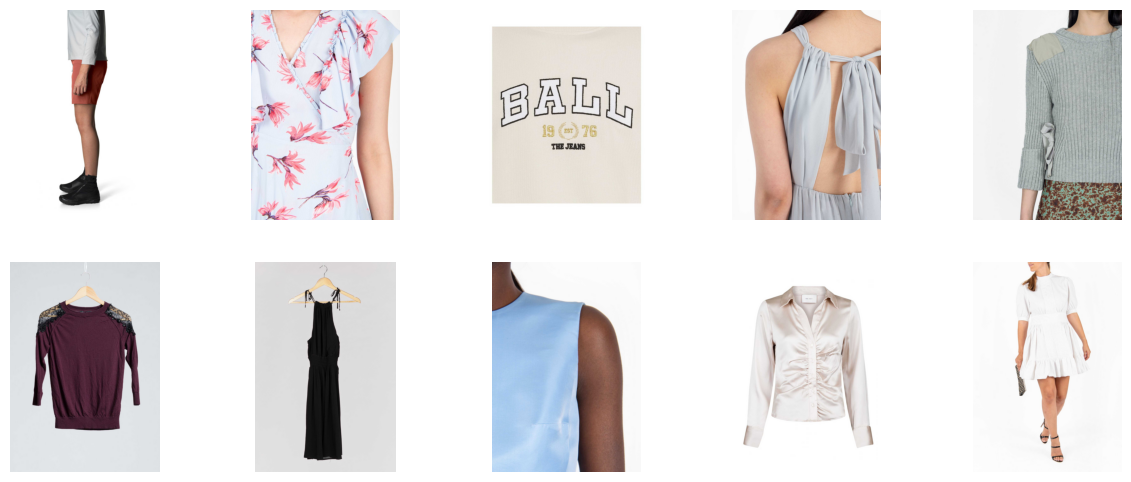

In [ ]:
import matplotlib.pyplot as plt
import random

sample = random.sample(os.listdir(cleaned_dir), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, name in zip(axes.flat, sample):
    ax.imshow(Image.open(os.path.join(cleaned_dir, name)))
    ax.axis("off")
plt.show()